In [1]:
PLAYERS = {
    "James":    (32, 40, 35),
    "Tatum":    (42, 33, 42),
    "Siakam":   (37, 42, 37),
    "Holmgren": (36, 37, 37),
    "Morant": (38, 28, 29),
    "Young": (39, 46, 37),
    "Brunson": (40, 30, 39),
    "Ball": (41, 38, 40),
    "Booker": (40, 33, 42),
    "Harden": (36, 36, 38),
    "Jokic": (57, 57, 59),
}

# Second draft: more complex case for F/SF or F/PF slots and G/PG or G/SG slots

In [2]:
"""
Lock-in optimizer: 1 specialized slot (e.g. SF) + H general F slots,
one game remaining per player.

  A = players eligible for the specialized slot (they can also play F)
  B = F-only players

Lock cases (following the write-up):
  1. No SF lock, m F locks, all from B, 0 <= m <= min(H, |B|):
       sum P_{M,1} + E[ max_{a in A} P_{a,2} ] + E[ top (H-m) of P_2 : player != a*, player not in M ]
     where a* is the SF picked in each simulation.
  2. One SF lock a in A, m F locks from everyone else, 0 <= m <= H:
       P_{a,1} + sum P_{M,1} + E[ top (H-m) of P_2 : player != a, player not in M ]
     m = H means everything is locked; those cases collapse into one row (the best).

Locking an SF player in an F slot while the SF slot is open is never better than
locking him in the SF slot, so those cases are skipped.
"""
import itertools
import numpy as np
import pandas as pd

CV = 0.30            # SD = CV * mean.  Set SD_RULE = "sqrt" to use SD = sqrt(mean)
SD_RULE = "cv"
N_SIMS = 500_000
SEED = 0

# player: (E[P_1], P_1 actual, E[P_2])
PLAYERS = {
    "Jokic": (57, 57, 59),
    "Siakam":   (37, 42, 37),
    "Holmgren": (36, 37, 37),
}

SPECIAL = "C"                 # name of the specialized slot
NONSPECIAL = "UTIL"
H = 1                          # number of general F slots
A = ["Jokic"]         # eligible for the specialized slot (and F/G)
B = ["Siakam", "Holmgren"]     # F/G-only

# ---- checks ----
for p in A + B:
    if p not in PLAYERS:
        raise ValueError(f"{p} is in A or B but not in PLAYERS")
overlap = set(A) & set(B)
if overlap:
    raise ValueError(f"{overlap} listed in both A and B")

names = [p for p in PLAYERS if p in A or p in B]
idx = {p: i for i, p in enumerate(names)}
p1 = np.array([PLAYERS[p][1] for p in names], float)
mu2 = np.array([PLAYERS[p][2] for p in names], float)
sd2 = CV * mu2 if SD_RULE == "cv" else np.sqrt(mu2)

# Gamma draws for game 2 (non-negative, right-skewed), shared across all cases
rng = np.random.default_rng(SEED)
shape, scale = (mu2 / sd2) ** 2, sd2 ** 2 / mu2
draws = rng.gamma(shape, scale, size=(N_SIMS, len(names)))
zeros = np.zeros(N_SIMS)
rows_ix = np.arange(N_SIMS)


def top_k_sum(cols, k, exclude=None):
    """Per-simulation sum of the k largest scores among cols, optionally
    excluding one column per simulation (exclude = position within cols)."""
    if k <= 0 or not cols:
        return zeros
    sub = draws[:, cols].copy()
    available = len(cols)
    if exclude is not None:
        sub[rows_ix, exclude] = -np.inf
        available -= 1
    k = min(k, available)
    if k <= 0:
        return zeros
    return (-np.partition(-sub, k - 1, axis=1)[:, :k]).sum(axis=1)


def make_row(sf_lock, f_locks, sf_scores, f_scores, total_samples):
    locked = ([sf_lock] if sf_lock else []) + list(f_locks)
    placement = ([f"{sf_lock}→{SPECIAL}"] if sf_lock else []) + [f"{p}→{NONSPECIAL}" for p in f_locks]
    n_open_f = H - len(f_locks)
    open_slots = ([] if sf_lock else [SPECIAL]) + ([NONSPECIAL] * n_open_f)
    return {
        "locks": ", ".join(p for p in names if p in locked) or "(none)",
        "placement": ", ".join(placement) or "(none)",
        "#locks": len(locked),
        "open": ", ".join(open_slots) or "-",
        "locked pts": sum(p1[idx[p]] for p in locked),
        f"E[{SPECIAL}]": sf_scores.mean() if sf_scores is not None else np.nan,
        f"E[open {NONSPECIAL} total]": f_scores.mean() if n_open_f > 0 else np.nan,
        "total": total_samples.mean(),
        "note": "",
    }


cases = []          # (row, total_samples)

# ---- 1. no SF lock: m F locks from B ----
A_cols = [idx[a] for a in A]
sf_best = draws[:, A_cols].max(axis=1)              # best SF each simulation
sf_pick = draws[:, A_cols].argmax(axis=1)           # which A player it was
for m in range(min(H, len(B)) + 1):
    for M in itertools.combinations(B, m):
        locked_pts = sum(p1[idx[p]] for p in M)
        rest = [idx[p] for p in names if p not in M]
        pos_in_rest = np.array([rest.index(c) for c in A_cols])[sf_pick]   # exclude the SF pick
        f_scores = top_k_sum(rest, H - m, exclude=pos_in_rest)
        total = locked_pts + sf_best + f_scores
        cases.append((make_row(None, M, sf_best, f_scores, total), total))

# ---- 2. one SF lock a, m F locks from everyone else ----
seen = set()
full_locks = []
for a in A:
    others = [p for p in names if p != a]
    for m in range(min(H, len(others)) + 1):
        for M in itertools.combinations(others, m):
            key = frozenset((a,) + M)
            if key in seen:            # e.g. James→SF + Tatum→F == Tatum→SF + James→F
                continue
            seen.add(key)
            locked_pts = p1[idx[a]] + sum(p1[idx[p]] for p in M)
            rest = [idx[p] for p in others if p not in M]
            f_scores = top_k_sum(rest, H - m)
            total = locked_pts + f_scores
            entry = (make_row(a, M, None, f_scores, total), total)
            (full_locks if m == H else cases).append(entry)

# all slots locked: keep only the best one
if full_locks:
    best_row, best_total = max(full_locks, key=lambda c: c[0]["total"])
    best_row["note"] = f"best of {len(full_locks)} full-lock options"
    cases.append((best_row, best_total))

ordered = sorted(cases, key=lambda c: c[0]["#locks"])
df = pd.DataFrame([row for row, _ in ordered])
samples = [s for _, s in ordered]          # full simulated totals, aligned with df rows (for the box plot)

pd.set_option("display.width", 180)
print(df.round(2).to_string(index=False))

best = df.loc[df["total"].idxmax()]
print(f"\nBest: lock {best['placement']}  ->  expected total {best['total']:.2f}")

        locks            placement  #locks    open  locked pts  E[C]  E[open UTIL total]  total                        note
       (none)               (none)       0 C, UTIL         0.0 58.99                43.2 102.19                            
       Siakam          Siakam→UTIL       1       C        42.0 58.99                 NaN 100.99                            
     Holmgren        Holmgren→UTIL       1       C        37.0 58.99                 NaN  95.99                            
        Jokic              Jokic→C       1    UTIL        57.0   NaN                43.2 100.20                            
Jokic, Siakam Jokic→C, Siakam→UTIL       2       -        99.0   NaN                 NaN  99.00 best of 2 full-lock options

Best: lock (none)  ->  expected total 102.19


### Table View

In [3]:
# ---- Styled lock-case table (run after the main script; uses df, names, p1) ----
table = df[df["total"].notna()].reset_index(drop=True)

# placement "James→SF, Siakam→F"  ->  {"James": "SF", "Siakam": "F"}
locked = table["placement"].apply(
    lambda s: {} if s == "(none)" else dict(pair.split("→") for pair in s.split(", ")))

# locked cell shows the game-1 score and the slot it's locked into, e.g. "40 (SF)"
view = pd.DataFrame({p: [f"{p1[i]:g} ({L[p]})" if p in L else "" for L in locked]
                     for i, p in enumerate(names)})
view["Expected score"] = table["total"]

# lowest -> 3rd lowest (dark to light), highest -> 3rd highest (strong to pale)
BLUES = [("#08306b", "white"), ("#2171b5", "white"), ("#9ecae1", "black")]
REDS  = [("#a50f15", "white"), ("#ef3b2c", "white"), ("#fcbba1", "black")]

# dense rank on rounded scores, so tied cases share a shade
score = view["Expected score"].round(2)
low_rank  = score.rank(method="dense", ascending=True)    # 1 = lowest
high_rank = score.rank(method="dense", ascending=False)   # 1 = highest

# highlight up to 3 per side, but never more than half the distinct scores,
# so the blue and red groups can't overlap in small tables
N_HIGHLIGHT = min(3, score.nunique() // 2)

def style_table(_):
    s = pd.DataFrame("background-color: white; color: #222;", index=view.index, columns=view.columns)
    for r, L in locked.items():
        for p in L:
            s.loc[r, p] = "background-color: lightgray; color: black; font-weight: bold;"
    for r in view.index:
        if high_rank[r] <= N_HIGHLIGHT:
            bg, fg = REDS[int(high_rank[r]) - 1]
        elif low_rank[r] <= N_HIGHLIGHT:
            bg, fg = BLUES[int(low_rank[r]) - 1]
        else:
            continue
        s.loc[r, "Expected score"] = f"background-color: {bg}; color: {fg}; font-weight: bold;"
    return s

styled = (view.style
          .apply(style_table, axis=None)
          .format({"Expected score": "{:.2f}"})
          .set_properties(**{"text-align": "center", "padding": "6px 14px",
                             "border": "1px solid #bbb"})
          .set_table_styles([{"selector": "th",
                              "props": "background-color: #333; color: white; padding: 6px 14px;"}])
          .hide(axis="index"))
styled

Jokic,Siakam,Holmgren,Expected score
,,,102.19
,42 (UTIL),,100.99
,,37 (UTIL),95.99
57 (C),,,100.20
57 (C),42 (UTIL),,99.00


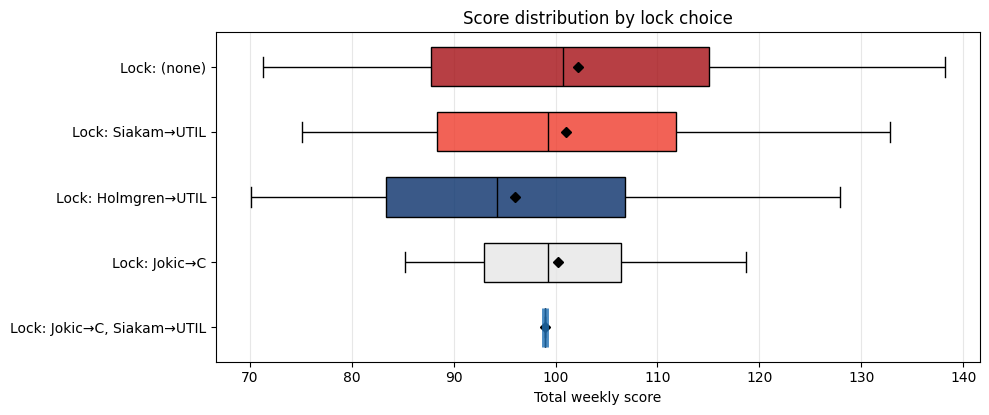

In [4]:
# ---- Seaborn box plots, 80% opacity (run after the table cell) ----
# uses df, samples (from the main script), BLUES, REDS, low_rank, high_rank, N_HIGHLIGHT
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgba

ALPHA = 0.8
PLOT_N = 100_000          # samples per case used for plotting (keeps the long table small)

feasible = df[df["total"].notna()].reset_index(drop=True)
# samples[i] is the full simulated total for row i of df, built in the main script
# with position eligibility, so it is not rebuilt here

# same colors as the table
def case_color(i):
    if high_rank[i] <= N_HIGHLIGHT:
        return REDS[int(high_rank[i]) - 1][0]
    if low_rank[i] <= N_HIGHLIGHT:
        return BLUES[int(low_rank[i]) - 1][0]
    return "#e6e6e6"

# show every case if there are 10 or fewer; otherwise the 5 highest and 5 lowest
MAX_SHOW, N_EACH = 10, 5
if len(feasible) > MAX_SHOW:
    by_score = np.argsort(feasible["total"].values, kind="stable")
    order = np.sort(np.concatenate([by_score[:N_EACH], by_score[-N_EACH:]]))   # keep table order
else:
    order = np.arange(len(feasible))                     # same row order as the table

# label each box with its slot placement, e.g. "Lock: James→SF, Siakam→F"
labels = [f"Lock: {feasible['placement'][i]}" for i in order]
palette = {labels[n]: case_color(i) for n, i in enumerate(order)}

long = pd.concat([pd.DataFrame({"case": labels[n], "score": samples[i][:PLOT_N]})
                  for n, i in enumerate(order)], ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 0.55 * len(order) + 1.5))   # height scales with number of boxes
sns.boxplot(data=long, x="score", y="case", hue="case", order=labels, palette=palette,
            legend=False, whis=(5, 95), showfliers=False, showmeans=True, width=0.6,
            saturation=1, linecolor="black", ax=ax,
            meanprops=dict(marker="D", markerfacecolor="black", markeredgecolor="black", markersize=5),
            medianprops=dict(color="black"))

# 80% opacity on the box fill only (edges stay solid)
for patch in ax.patches:
    patch.set_facecolor(to_rgba(patch.get_facecolor(), ALPHA))

# fully locked cases have zero spread: draw them as a thick colored line
for y, i in enumerate(order):
    if np.ptp(samples[i]) == 0:
        ax.vlines(samples[i][0], y - 0.3, y + 0.3, color=case_color(i), linewidth=5, alpha=ALPHA, zorder=3)

ax.set_xlabel("Total weekly score")
ax.set_ylabel("")
ax.set_title("Score distribution by lock choice")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# First complex case

In [5]:
"""
Lock-in optimizer, one game remaining per player.

For each lock set L with |L| < slots, k = slots - |L| open slots:
    Total = sum_{i in L} P_{i,1}  +  m_1 + m_2 + ... + m_k
where m_j = E[j-th largest of {P_{player,2} : player not in L}].

When every slot is locked there is no randomness left, so the best full lock
is simply the players with the highest game-1 scores. Those cases are
collapsed into a single row.
"""
import itertools
import numpy as np
import pandas as pd

SLOTS = 1
CV = 0.30            # SD = CV * mean.  Set SD_RULE = "sqrt" to use SD = sqrt(mean)
SD_RULE = "cv"
N_SIMS = 500_000
SEED = 0

# player: (E[P_1], P_1 actual, E[P_2])
PLAYERS = {
    "Siakam":  (37, 42, 37),
    "Holgrem": (37, 35, 37),
    "James":   (32, 40, 35),
    "Tatum":   (33, 42, 42),
}

names = list(PLAYERS)
p1 = np.array([PLAYERS[p][1] for p in names], float)
mu2 = np.array([PLAYERS[p][2] for p in names], float)
sd2 = CV * mu2 if SD_RULE == "cv" else np.sqrt(mu2)

# Gamma draws for game 2 (non-negative, right-skewed), shared across all cases
rng = np.random.default_rng(SEED)
shape, scale = (mu2 / sd2) ** 2, sd2 ** 2 / mu2
draws = rng.gamma(shape, scale, size=(N_SIMS, len(names)))

n_full = min(SLOTS, len(names))          # number of locks that fills every usable slot

def make_row(L, note=""):
    rest = [i for i in range(len(names)) if i not in L]
    k = min(SLOTS - len(L), len(rest))
    locked_pts = p1[list(L)].sum()
    m = [np.nan] * SLOTS
    if k > 0:
        order = -np.sort(-draws[:, rest], axis=1)            # descending
        for j in range(k):
            m[j] = order[:, j].mean()                        # E[j-th largest]
    return {
        "locks": ", ".join(names[i] for i in L) or "(none)",
        "#locks": len(L),
        "k open": k,
        "locked pts": locked_pts,
        **{f"m{j+1}": m[j] for j in range(SLOTS)},
        "total": locked_pts + np.nansum(m[:k]),
        "note": note,
    }

rows = []
# every partial-lock case (some slots still open)
for r in range(n_full):
    for L in itertools.combinations(range(len(names)), r):
        rows.append(make_row(L))

# all slots locked: one row, the highest game-1 scores
best_full = tuple(sorted(np.argsort(-p1, kind="stable")[:n_full]))
n_options = len(list(itertools.combinations(range(len(names)), n_full)))
rows.append(make_row(best_full, note=f"best of {n_options} full-lock options"))

df = pd.DataFrame(rows)
pd.set_option("display.width", 160)
print(df.round(2).to_string(index=False))

best = df.loc[df["total"].idxmax()]
print(f"\nBest: lock {best['locks']}  ->  expected total {best['total']:.2f}")

 locks  #locks  k open  locked pts   m1  total                        note
(none)       0       1         0.0 50.4   50.4                            
Siakam       1       0        42.0  NaN   42.0 best of 4 full-lock options

Best: lock (none)  ->  expected total 50.40


### Table View

In [6]:
# ---- Styled lock-case table (run after the main script; uses df, names, p1) ----
table = df[df["total"].notna()].reset_index(drop=True)
locked = table["locks"].apply(lambda s: set() if s == "(none)" else set(s.split(", ")))

view = pd.DataFrame({p: [f"{p1[i]:g}" if p in L else "" for L in locked]
                     for i, p in enumerate(names)})
view["Expected score"] = table["total"]

# lowest -> 3rd lowest (dark to light), highest -> 3rd highest (strong to pale)
BLUES = [("#2171b5", "white"), ("#9ecae1", "black")]   # lowest, 2nd lowest
REDS  = [("#ef3b2c", "white"), ("#fcbba1", "black")]   # highest, 2nd highest

# dense rank on rounded scores, so tied cases share a shade
score = view["Expected score"].round(2)
low_rank  = score.rank(method="dense", ascending=True)    # 1 = lowest
high_rank = score.rank(method="dense", ascending=False)   # 1 = highest

# highlight up to 3 per side, but never more than half the distinct scores,
# so the blue and red groups can't overlap in small tables
N_HIGHLIGHT = min(2, score.nunique() // 2)

def style_table(_):
    s = pd.DataFrame("background-color: white; color: #222;", index=view.index, columns=view.columns)
    for r, L in locked.items():
        for p in L:
            s.loc[r, p] = "background-color: lightgray; color: black; font-weight: bold;"
    for r in view.index:
        if high_rank[r] <= N_HIGHLIGHT:
            bg, fg = REDS[int(high_rank[r]) - 1]
        elif low_rank[r] <= N_HIGHLIGHT:
            bg, fg = BLUES[int(low_rank[r]) - 1]
        else:
            continue
        s.loc[r, "Expected score"] = f"background-color: {bg}; color: {fg}; font-weight: bold;"
    return s

styled = (view.style
          .apply(style_table, axis=None)
          .format({"Expected score": "{:.2f}"})
          .set_properties(**{"text-align": "center", "padding": "6px 14px",
                             "border": "1px solid #bbb"})
          .set_table_styles([{"selector": "th",
                              "props": "background-color: #333; color: white; padding: 6px 14px;"}])
          .hide(axis="index"))
styled

Siakam,Holgrem,James,Tatum,Expected score
,,,,50.40
42,,,,42.00


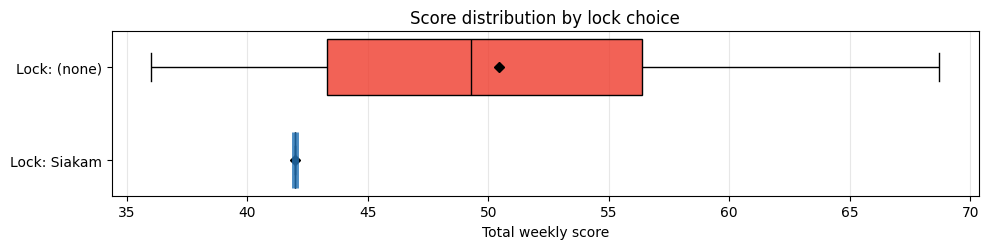

In [7]:
# ---- Seaborn box plots, 80% opacity (run after the table cell) ----
# uses df, draws, names, p1, SLOTS, N_SIMS, BLUES, REDS, low_rank, high_rank, N_HIGHLIGHT
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgba

ALPHA = 0.8
PLOT_N = 100_000          # samples per case used for plotting (keeps the long table small)

feasible = df[df["total"].notna()].reset_index(drop=True)

# rebuild the full simulated total for every case
samples = []
for locks in feasible["locks"]:
    L = [] if locks == "(none)" else [names.index(p) for p in locks.split(", ")]
    rest = [i for i in range(len(names)) if i not in L]
    k = min(SLOTS - len(L), len(rest))
    total = np.full(N_SIMS, p1[L].sum() if L else 0.0)
    if k > 0:
        total = total + (-np.sort(-draws[:, rest], axis=1))[:, :k].sum(axis=1)
    samples.append(total)

# same colors as the table
def case_color(i):
    if high_rank[i] <= N_HIGHLIGHT:
        return REDS[int(high_rank[i]) - 1][0]
    if low_rank[i] <= N_HIGHLIGHT:
        return BLUES[int(low_rank[i]) - 1][0]
    return "#e6e6e6"

# show every case if there are 10 or fewer; otherwise the 5 highest and 5 lowest
MAX_SHOW, N_EACH = 10, 5
if len(feasible) > MAX_SHOW:
    by_score = np.argsort(feasible["total"].values, kind="stable")
    order = np.sort(np.concatenate([by_score[:N_EACH], by_score[-N_EACH:]]))   # keep table order
else:
    order = np.arange(len(feasible))                     # same row order as the table
labels = [f"Lock: {feasible['locks'][i]}" for i in order]
palette = {f"Lock: {feasible['locks'][i]}": case_color(i) for i in order}

long = pd.concat([pd.DataFrame({"case": f"Lock: {feasible['locks'][i]}",
                                "score": samples[i][:PLOT_N]}) for i in order],
                 ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 0.55 * len(order) + 1.5))   # height scales with number of boxes
sns.boxplot(data=long, x="score", y="case", hue="case", order=labels, palette=palette,
            legend=False, whis=(5, 95), showfliers=False, showmeans=True, width=0.6,
            saturation=1, linecolor="black", ax=ax,
            meanprops=dict(marker="D", markerfacecolor="black", markeredgecolor="black", markersize=5),
            medianprops=dict(color="black"))

# 80% opacity on the box fill only (edges stay solid)
for patch in ax.patches:
    patch.set_facecolor(to_rgba(patch.get_facecolor(), ALPHA))

# fully locked cases have zero spread: draw them as a thick colored line
for y, i in enumerate(order):
    if np.ptp(samples[i]) == 0:
        ax.vlines(samples[i][0], y - 0.3, y + 0.3, color=case_color(i), linewidth=5, alpha=ALPHA, zorder=3)

ax.set_xlabel("Total weekly score")
ax.set_ylabel("")
ax.set_title("Score distribution by lock choice")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()